# Xenium marker expression and coexpression before and after Syndri cleaning

This notebook uses the same 19 annotated breast Xenium slices selected in `figures/Figure1_SpilloverLocalization.ipynb`, together with the matched Chromium single-cell reference. The matching files in `results/final` provide raw counts in `X`, Syndri probabilities in `layers['syndri_admix_probs_X']`, and SPLIT counts in `layers['split_purified_counts_X']`; the reference panel uses its SoupX count layer.

Cleaning uses the project's count-weighted, cell-type-specific target-removed-fraction rule. Dot size is the fraction of cells expressing a gene; color is mean log1p-normalized expression on its original scale. One shared color range is used across the reference, raw Xenium, Syndri, and SPLIT panels.

In [9]:
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
from matplotlib.lines import Line2D

INTERIM_DIR = Path('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/interim/spatial')
RESULTS_DIR = Path('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/final')
REFERENCE_PATH = Path('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/interim/single-cell/breast_cancer_chromium_genesubset.h5ad')
OUTPUT_DIR = Path('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/dotplots')
SLICE_PATTERN = 'GSM950*_rctd_annotated.h5ad'
TARGET_REMOVED_FRACTION = 0.50
TARGET_SUM = 10_000
MIN_CELLS_PER_TYPE = 50
DETECTION_THRESHOLD = 0.0  # Transformed counts > 0 are treated as detected
import pandas as pd
gene_annot = pd.read_excel('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/raw/single-cell/41592_2026_3089_MOESM4_ESM.xlsx',sheet_name='ST 4',skiprows=1)
# gene_annot = gene_annot[gene_annot['Annotation_DB']=='malignant cell']
print(gene_annot)
MARKER_GENES = (
    gene_annot.groupby("Annotation_DB")["Genes"]
    .agg(lambda values: list(pd.unique(values.dropna())))
    .to_dict()
)

MARKER_GENES = {k:v[:2] for k,v in MARKER_GENES.items()}
print(MARKER_GENES)

# Edit this ordered dictionary to change the displayed marker panel. Missing genes are reported and skipped.
MARKER_GENES = {
    'Tumor / epithelial': ['EPCAM', 'KRT8', 'KRT18', 'KRT19'],
    'T cell': ['CD3D', 'CD3E', 'TRBC1', 'IL7R'],
    'B cell': ['CD79A', 'MS4A1', 'CD37', 'CD74'],
    'Myeloid': ['LYZ', 'FCER1G', 'TYROBP', 'C1QC'],
    'Endothelial': ['PECAM1', 'VWF', 'EMCN', 'KDR'],
    'Fibroblast': ['COL1A1', 'COL1A2', 'DCN', 'COL3A1'],
}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='paper')

      Genes       Ensembl_ID  Num_Probesets  Codewords  \
0    ABCC11  ENSG00000121270              7          1   
1     ACTA2  ENSG00000107796              8          1   
2     ACTG2  ENSG00000163017              8          1   
3     ADAM9  ENSG00000168615              8          1   
4    ADGRE5  ENSG00000123146              8          1   
..      ...              ...            ...        ...   
275     VWF  ENSG00000110799              8          1   
276    WARS  ENSG00000140105              8          1   
277    ZEB1  ENSG00000148516              8          1   
278    ZEB2  ENSG00000169554              8          1   
279  ZNF562  ENSG00000171466              8          1   

                     Annotation       Annotation_DB  
0                 Breast cancer      malignant cell  
1           Smooth muscle cells  smooth muscle cell  
2    Breast myoepithelial cells     epithelial cell  
3        Breast glandular cells     epithelial cell  
4               Dendritic cells  

In [31]:
marker_genes_deseq2 = pd.read_csv('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/markers/pydeseq2/hierarchical/cell_type_marker_genes_deseq2.csv')
marker_genes_deseq2

,gene,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,stage,parent_group,cell_type,n_patients,n_enriched_targets,target_detection_fraction,max_other_detection_fraction,other_to_target_detection_ratio
0,ENSG00000176435,493.698703,7.018187,0.627964,11.176095,5.338771e-29,1.243934e-26,flat,__all__,capillary endothelial cell,3,1,0.410653,0.031802,0.077443
1,ENSG00000110799,968.585496,6.722600,0.619193,10.857028,1.846619e-27,2.151311e-25,flat,__all__,capillary endothelial cell,3,1,0.527491,0.046875,0.088864
2,ENSG00000203883,293.196781,6.799075,0.654194,10.393052,2.666817e-25,2.071228e-23,flat,__all__,capillary endothelial cell,3,1,0.285223,0.017668,0.061944
3,ENSG00000173269,276.852709,6.297590,0.656871,9.587257,9.045780e-22,5.269167e-20,flat,__all__,capillary endothelial cell,3,1,0.314433,0.045936,0.146093
4,ENSG00000125810,656.534306,5.728041,0.620840,9.226282,2.801901e-20,9.913023e-19,flat,__all__,capillary endothelial cell,3,1,0.518900,0.232877,0.448789
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62,ENSG00000117090,77.009768,3.676164,0.973978,3.774379,1.604066e-04,8.757335e-04,flat,__all__,natural T-regulatory cell,3,1,0.392330,0.206349,0.525958
63,ENSG00000182010,91.852807,3.259866,1.015163,3.211176,1.321930e-03,3.926908e-03,flat,__all__,natural T-regulatory cell,3,1,0.353982,0.051587,0.145734
64,ENSG00000166148,78.428251,7.407231,0.789432,9.382982,6.413255e-21,1.391676e-18,flat,__all__,pericyte,3,1,0.159011,0.004098,0.025774
65,ENSG00000176692,81.538695,6.566628,0.743899,8.827312,1.072210e-18,1.163348e-16,flat,__all__,pericyte,3,1,0.123675,0.011538,0.093297


## Match the Figure 1 slice cohort

In [15]:
figure1_paths = sorted(INTERIM_DIR.glob(SLICE_PATTERN))
if not figure1_paths:
    raise FileNotFoundError(f'No Figure 1 inputs matching {SLICE_PATTERN!r} in {INTERIM_DIR}')

slice_paths = [RESULTS_DIR / path.name for path in figure1_paths]
missing = [path for path in slice_paths if not path.exists()]
if missing:
    raise FileNotFoundError(f'Missing matching final AnnData files: {missing}')

print(f'Using {len(slice_paths)} Xenium slices (exactly matching the Figure 1 cohort):')
display(pd.DataFrame({'slice': [p.name.removesuffix("_rctd_annotated.h5ad") for p in slice_paths]}))

Using 19 Xenium slices (exactly matching the Figure 1 cohort):


,slice
0,GSM9509156_breast_breast_B17_B17
1,GSM9509157_breast_breast_B16_B16
2,GSM9509158_breast_breast_B15_B15
3,GSM9509159_breast_breast_B14_B14
4,GSM9509160_breast_breast_B2_B2
5,GSM9509161_breast_breast_B13_B13
6,GSM9509162_breast_breast_B12_B12
7,GSM9509163_breast_breast_B11_B11
8,GSM9509164_breast_breast_B10_B10
9,GSM9509165_breast_breast_B4_B4


## Cleaning and dot-plot summary helpers

In [16]:
def to_csr(X):
    if sp.issparse(X):
        return X.tocsr().astype(np.float32)
    return sp.csr_matrix(np.asarray(X, dtype=np.float32))


def threshold_for_removed_fraction(probabilities, counts, target_fraction):
    """Count-weighted threshold selection used in eval/metrics_eval.py."""
    counts = to_csr(counts)
    rows, cols = counts.nonzero()
    weights = counts.data.astype(float)
    pvals = np.asarray(probabilities[rows, cols]).ravel().astype(float)
    valid = np.isfinite(pvals) & np.isfinite(weights) & (weights > 0)
    pvals, weights = pvals[valid], weights[valid]
    if weights.size == 0:
        return np.inf, 0.0
    order = np.argsort(pvals)[::-1]
    p_sorted, w_sorted = pvals[order], weights[order]
    index = min(
        int(np.searchsorted(np.cumsum(w_sorted), target_fraction * w_sorted.sum(), side='left')),
        len(p_sorted) - 1,
    )
    threshold = float(p_sorted[index])
    achieved = float(w_sorted[p_sorted >= threshold].sum() / w_sorted.sum())
    return threshold, achieved


def clean_by_cell_type(counts, probabilities, labels, target_fraction):
    cleaned = to_csr(counts).copy()
    labels = np.asarray(labels, dtype=str)
    row_thresholds = np.full(cleaned.shape[0], np.inf)
    records = []
    for cell_type in pd.unique(labels):
        mask = labels == cell_type
        threshold, achieved = threshold_for_removed_fraction(
            probabilities[mask], cleaned[mask], target_fraction
        )
        row_thresholds[mask] = threshold
        records.append({
            'cell_type': cell_type, 'n_cells': int(mask.sum()),
            'admix_prob_threshold': threshold,
            'achieved_removed_fraction': achieved,
        })
    rows, cols = cleaned.nonzero()
    pvals = np.asarray(probabilities[rows, cols]).ravel()
    cleaned.data[pvals >= row_thresholds[rows]] = 0
    cleaned.eliminate_zeros()
    return cleaned, pd.DataFrame(records)


def log_normalize(counts, target_sum=TARGET_SUM, totals=None):
    counts = to_csr(counts).copy()
    if totals is None:
        totals = np.asarray(counts.sum(axis=1)).ravel()
    else:
        totals = np.asarray(totals, dtype=float).ravel()
        if len(totals) != counts.shape[0]:
            raise ValueError('Normalization totals must have one value per cell')
    scale = np.divide(target_sum, totals, out=np.zeros_like(totals, dtype=float), where=totals > 0)
    normalized = sp.diags(scale) @ counts
    normalized.data = np.log1p(normalized.data)
    return normalized.tocsr()


def summarize_matrix(
    counts, labels, genes, condition, slice_id, *, normalization_totals=None,
    detection_threshold=DETECTION_THRESHOLD,
):
    normalized = log_normalize(counts, totals=normalization_totals)
    labels = np.asarray(labels, dtype=str)
    rows = []
    for cell_type in pd.unique(labels):
        mask = labels == cell_type
        X_ct = counts[mask]
        Xn_ct = normalized[mask]
        mean_expression = np.asarray(Xn_ct.mean(axis=0)).ravel()
        fraction_expressing = np.asarray((X_ct > detection_threshold).mean(axis=0)).ravel()
        for gene, mean, fraction in zip(genes, mean_expression, fraction_expressing):
            rows.append({
                'slice': slice_id, 'condition': condition, 'cell_type': cell_type,
                'gene': gene, 'n_cells': int(mask.sum()),
                'mean_expression': float(mean),
                'fraction_expressing': float(fraction),
            })
    return pd.DataFrame(rows)

In [17]:
# Select coexpression genes from the loaded hierarchical marker file.
# A gene appearing in multiple groups is assigned to its first hierarchy group.
hierarchical_markers = (
    marker_genes_deseq2[['gene', 'stage', 'parent_group', 'cell_type']]
    .dropna(subset=['gene'])
    .assign(gene=lambda frame: frame['gene'].astype(str).str.strip())
    .loc[lambda frame: frame['gene'].ne('')]
    .sort_values(['stage', 'parent_group', 'cell_type', 'gene'], kind='stable')
    .drop_duplicates('gene', keep='first')
)
COEXPRESSION_GENES_BY_GROUP = (
    hierarchical_markers.groupby(
        ['stage', 'parent_group', 'cell_type'], sort=False
    )['gene'].agg(list).to_dict()
)
coexpression_requested_genes = [
    gene for genes in COEXPRESSION_GENES_BY_GROUP.values() for gene in genes
]
print(
    f'Loaded {len(coexpression_requested_genes)} unique hierarchical marker IDs '
    f'across {len(COEXPRESSION_GENES_BY_GROUP)} groups'
)

Loaded 67 unique hierarchical marker IDs across 6 groups


In [22]:
adata.var['ensembl_id'] = adata.var['id'].copy()

## Process all slices

Statistics are first computed per slice. The next section pools them with cell-count weighting, preventing a small slice and a large slice from contributing equally.

In [25]:
requested_genes = [gene for group in MARKER_GENES.values() for gene in group]
summary_frames, threshold_frames = [], []
genes_use = None
coexpression_genes_use = None
coexpression_gene_idx = None
coexpression_gene_labels = None
reference_var_names = None
reference_ensembl_ids = None
coexpression_stats = {}

for number, path in enumerate(slice_paths, start=1):
    print(f'[{number:02d}/{len(slice_paths):02d}] {path.name}')
    adata = ad.read_h5ad(path)
    adata.var['ensembl_id'] = adata.var['id'].copy()
    required_layers = {'syndri_admix_probs_X', 'split_purified_counts_X'}
    missing_layers = required_layers - set(adata.layers)
    if missing_layers or 'harmony_cell_type' not in adata.obs:
        raise KeyError(f'{path.name}: missing layers {sorted(missing_layers)} or obs[harmony_cell_type]')
    adata.var = adata.var.set_index('feature_name')
    current_var_names = adata.var_names.astype(str).tolist()
    if 'ensembl_id' not in adata.var:
        raise KeyError(f'{path.name}: var[ensembl_id] is required for hierarchical markers')
    current_ensembl_ids = adata.var['ensembl_id'].astype(str).tolist()
    if reference_var_names is None:
        reference_var_names = current_var_names
        reference_ensembl_ids = current_ensembl_ids
        genes_use = [gene for gene in requested_genes if gene in set(reference_var_names)]
        missing_genes = [gene for gene in requested_genes if gene not in set(reference_var_names)]
        print(f'Using {len(genes_use)} markers; missing markers skipped: {missing_genes}')
        ensembl_to_idx = {gene: idx for idx, gene in enumerate(reference_ensembl_ids)}
        coexpression_genes_use = [
            gene for gene in coexpression_requested_genes if gene in ensembl_to_idx
        ]
        missing_coexpression_genes = [
            gene for gene in coexpression_requested_genes if gene not in ensembl_to_idx
        ]
        if not coexpression_genes_use:
            raise ValueError('No hierarchical marker IDs occur in the Xenium panel')
        coexpression_gene_idx = np.array(
            [ensembl_to_idx[gene] for gene in coexpression_genes_use], dtype=int
        )
        coexpression_gene_labels = [
            reference_var_names[idx] for idx in coexpression_gene_idx
        ]
        print(
            f'Using {len(coexpression_genes_use)} hierarchical markers for coexpression; '
            f'{len(missing_coexpression_genes)} markers absent from Xenium skipped'
        )
        coexpression_stats = {
            condition: {
                'n_cells': 0,
                'cross_product': np.zeros(
                    (len(coexpression_genes_use), len(coexpression_genes_use)), dtype=np.float64
                ),
            }
            for condition in ('Original', 'Syndri cleaned')
        }
    elif (current_var_names != reference_var_names
          or current_ensembl_ids != reference_ensembl_ids):
        raise ValueError(f'{path.name}: gene names or Ensembl IDs differ from the first slice')

    gene_idx = np.array([reference_var_names.index(gene) for gene in genes_use])
    raw = to_csr(adata.X)
    probabilities = adata.layers['syndri_admix_probs_X']
    probabilities = probabilities.toarray() if sp.issparse(probabilities) else np.asarray(probabilities)
    labels = adata.obs['harmony_cell_type'].astype(str).to_numpy()
    cleaned, thresholds = clean_by_cell_type(raw, probabilities, labels, TARGET_REMOVED_FRACTION)
    split_counts = to_csr(adata.layers['split_purified_counts_X'])

    # Use the original full-panel library size for every spatial method.
    # This preserves removed count mass instead of renormalizing it away.
    raw_totals = np.asarray(raw.sum(axis=1)).ravel()
    for condition, counts in (('Original', raw), ('Syndri cleaned', cleaned)):
        # Count cells positive for each gene pair without concatenating all
        # 19 slices in memory. The diagonal is each gene's positive fraction.
        detected = (
            counts[:, coexpression_gene_idx] > DETECTION_THRESHOLD
        ).astype(np.float64)
        stats = coexpression_stats[condition]
        stats['n_cells'] += detected.shape[0]
        stats['cross_product'] += (detected.T @ detected).toarray()
    slice_id = path.name.removesuffix('_rctd_annotated.h5ad')
    thresholds.insert(0, 'slice', slice_id)
    threshold_frames.append(thresholds)
    summary_frames.append(summarize_matrix(
        raw[:, gene_idx], labels, genes_use, 'Before', slice_id,
        normalization_totals=raw_totals,
    ))
    summary_frames.append(summarize_matrix(
        cleaned[:, gene_idx], labels, genes_use, 'After Syndri', slice_id,
        normalization_totals=raw_totals,
    ))
    summary_frames.append(summarize_matrix(
        split_counts[:, gene_idx], labels, genes_use, 'SPLIT', slice_id,
        normalization_totals=raw_totals,
    ))
    del adata, raw, probabilities, cleaned, split_counts

slice_summary = pd.concat(summary_frames, ignore_index=True)
thresholds_df = pd.concat(threshold_frames, ignore_index=True)
slice_summary.to_csv(OUTPUT_DIR / 'xenium_before_after_dotplot_by_slice.csv', index=False)
thresholds_df.to_csv(OUTPUT_DIR / 'xenium_syndri_thresholds.csv', index=False)
display(thresholds_df.groupby('cell_type').agg(
    slices=('slice', 'nunique'), median_threshold=('admix_prob_threshold', 'median'),
    mean_removed_fraction=('achieved_removed_fraction', 'mean')
).round(3))

[01/19] GSM9509156_breast_breast_B17_B17_rctd_annotated.h5ad
Using 12 markers; missing markers skipped: ['KRT18', 'KRT19', 'CD3D', 'TRBC1', 'CD37', 'CD74', 'TYROBP', 'EMCN', 'COL1A1', 'COL1A2', 'DCN', 'COL3A1']
Using 67 hierarchical markers for coexpression; 0 markers absent from Xenium skipped
[02/19] GSM9509157_breast_breast_B16_B16_rctd_annotated.h5ad
[03/19] GSM9509158_breast_breast_B15_B15_rctd_annotated.h5ad
[04/19] GSM9509159_breast_breast_B14_B14_rctd_annotated.h5ad
[05/19] GSM9509160_breast_breast_B2_B2_rctd_annotated.h5ad
[06/19] GSM9509161_breast_breast_B13_B13_rctd_annotated.h5ad
[07/19] GSM9509162_breast_breast_B12_B12_rctd_annotated.h5ad
[08/19] GSM9509163_breast_breast_B11_B11_rctd_annotated.h5ad
[09/19] GSM9509164_breast_breast_B10_B10_rctd_annotated.h5ad
[10/19] GSM9509165_breast_breast_B4_B4_rctd_annotated.h5ad
[11/19] GSM9509166_breast_breast_B9_B9_rctd_annotated.h5ad
[12/19] GSM9509167_breast_breast_B8_B8_rctd_annotated.h5ad
[13/19] GSM9509168_breast_breast_B7_B7_rc

,slices,median_threshold,mean_removed_fraction
cell_type,,,
"CD4-positive, alpha-beta memory T cell",19,0.976,0.5
capillary endothelial cell,19,0.918,0.5
classical monocyte,19,0.978,0.5
cytotoxic T cell,19,0.980,0.5
fibroblast of breast,19,0.977,0.5
fibroblast of lung,19,0.851,0.5
macrophage,19,0.941,0.5
malignant cell,19,0.628,0.5
mast cell,19,0.992,0.5


## Pool slice summaries and draw before/after dot plots

In [26]:
def weighted_mean(group, column):
    return np.average(group[column], weights=group['n_cells'])


pooled_rows = []
for keys, group in slice_summary.groupby(['condition', 'cell_type', 'gene'], sort=False):
    pooled_rows.append({
        'condition': keys[0], 'cell_type': keys[1], 'gene': keys[2],
        'n_cells': int(group['n_cells'].sum()),
        'mean_expression': weighted_mean(group, 'mean_expression'),
        'fraction_expressing': weighted_mean(group, 'fraction_expressing'),
    })
pooled = pd.DataFrame(pooled_rows)

cell_counts = pooled[['cell_type', 'n_cells']].drop_duplicates()['cell_type'].value_counts()
if (cell_counts > 1).any():
    raise AssertionError('Cell counts differ between conditions')
cell_type_sizes = pooled[['cell_type', 'n_cells']].drop_duplicates().set_index('cell_type')['n_cells']
cell_type_order = cell_type_sizes[cell_type_sizes >= MIN_CELLS_PER_TYPE].sort_values(ascending=False).index.tolist()
pooled = pooled[pooled['cell_type'].isin(cell_type_order)].copy()

# Add the matched Chromium reference. SoupX contains its corrected count matrix.
reference = ad.read_h5ad(REFERENCE_PATH)
if 'SoupX' not in reference.layers or 'cell_type' not in reference.obs:
    raise KeyError("Reference requires layers['SoupX'] and obs['cell_type']")
reference_features = reference.var['feature_name'].astype(str).tolist()
reference_gene_to_idx = {gene: idx for idx, gene in enumerate(reference_features)}
missing_reference_genes = [gene for gene in genes_use if gene not in reference_gene_to_idx]
if missing_reference_genes:
    raise ValueError(f'Reference is missing marker genes: {missing_reference_genes}')
reference_gene_idx = np.array([reference_gene_to_idx[gene] for gene in genes_use])
reference_labels = reference.obs['cell_type'].astype(str).to_numpy()
reference_all_counts = to_csr(reference.layers['SoupX'])
reference_totals = np.asarray(reference_all_counts.sum(axis=1)).ravel()
reference_counts = reference_all_counts[:, reference_gene_idx]
reference_summary = summarize_matrix(
    reference_counts, reference_labels, genes_use, 'scRNA reference', 'Chromium reference',
    normalization_totals=reference_totals,
)
reference_summary = reference_summary[reference_summary['cell_type'].isin(cell_type_order)].drop(columns='slice')
pooled = pd.concat([pooled, reference_summary], ignore_index=True)
del reference, reference_all_counts, reference_counts

# mean_expression is the mean log1p-normalized expression computed above.
# Keep it on its original scale rather than scaling each gene to [0, 1].
pooled.to_csv(OUTPUT_DIR / 'xenium_before_after_dotplot_pooled.csv', index=False)
display(pooled.head())

,condition,cell_type,gene,n_cells,mean_expression,fraction_expressing
0,Before,capillary endothelial cell,EPCAM,93106,0.705264,0.148336
1,Before,capillary endothelial cell,KRT8,93106,2.301959,0.439284
2,Before,capillary endothelial cell,CD3E,93106,0.271781,0.056559
3,Before,capillary endothelial cell,IL7R,93106,0.273535,0.056001
4,Before,capillary endothelial cell,CD79A,93106,0.057190,0.012620


In [27]:
MARKER_GENES

{'Tumor / epithelial': ['EPCAM', 'KRT8', 'KRT18', 'KRT19'],
 'T cell': ['CD3D', 'CD3E', 'TRBC1', 'IL7R'],
 'B cell': ['CD79A', 'MS4A1', 'CD37', 'CD74'],
 'Myeloid': ['LYZ', 'FCER1G', 'TYROBP', 'C1QC'],
 'Endothelial': ['PECAM1', 'VWF', 'EMCN', 'KDR'],
 'Fibroblast': ['COL1A1', 'COL1A2', 'DCN', 'COL3A1']}

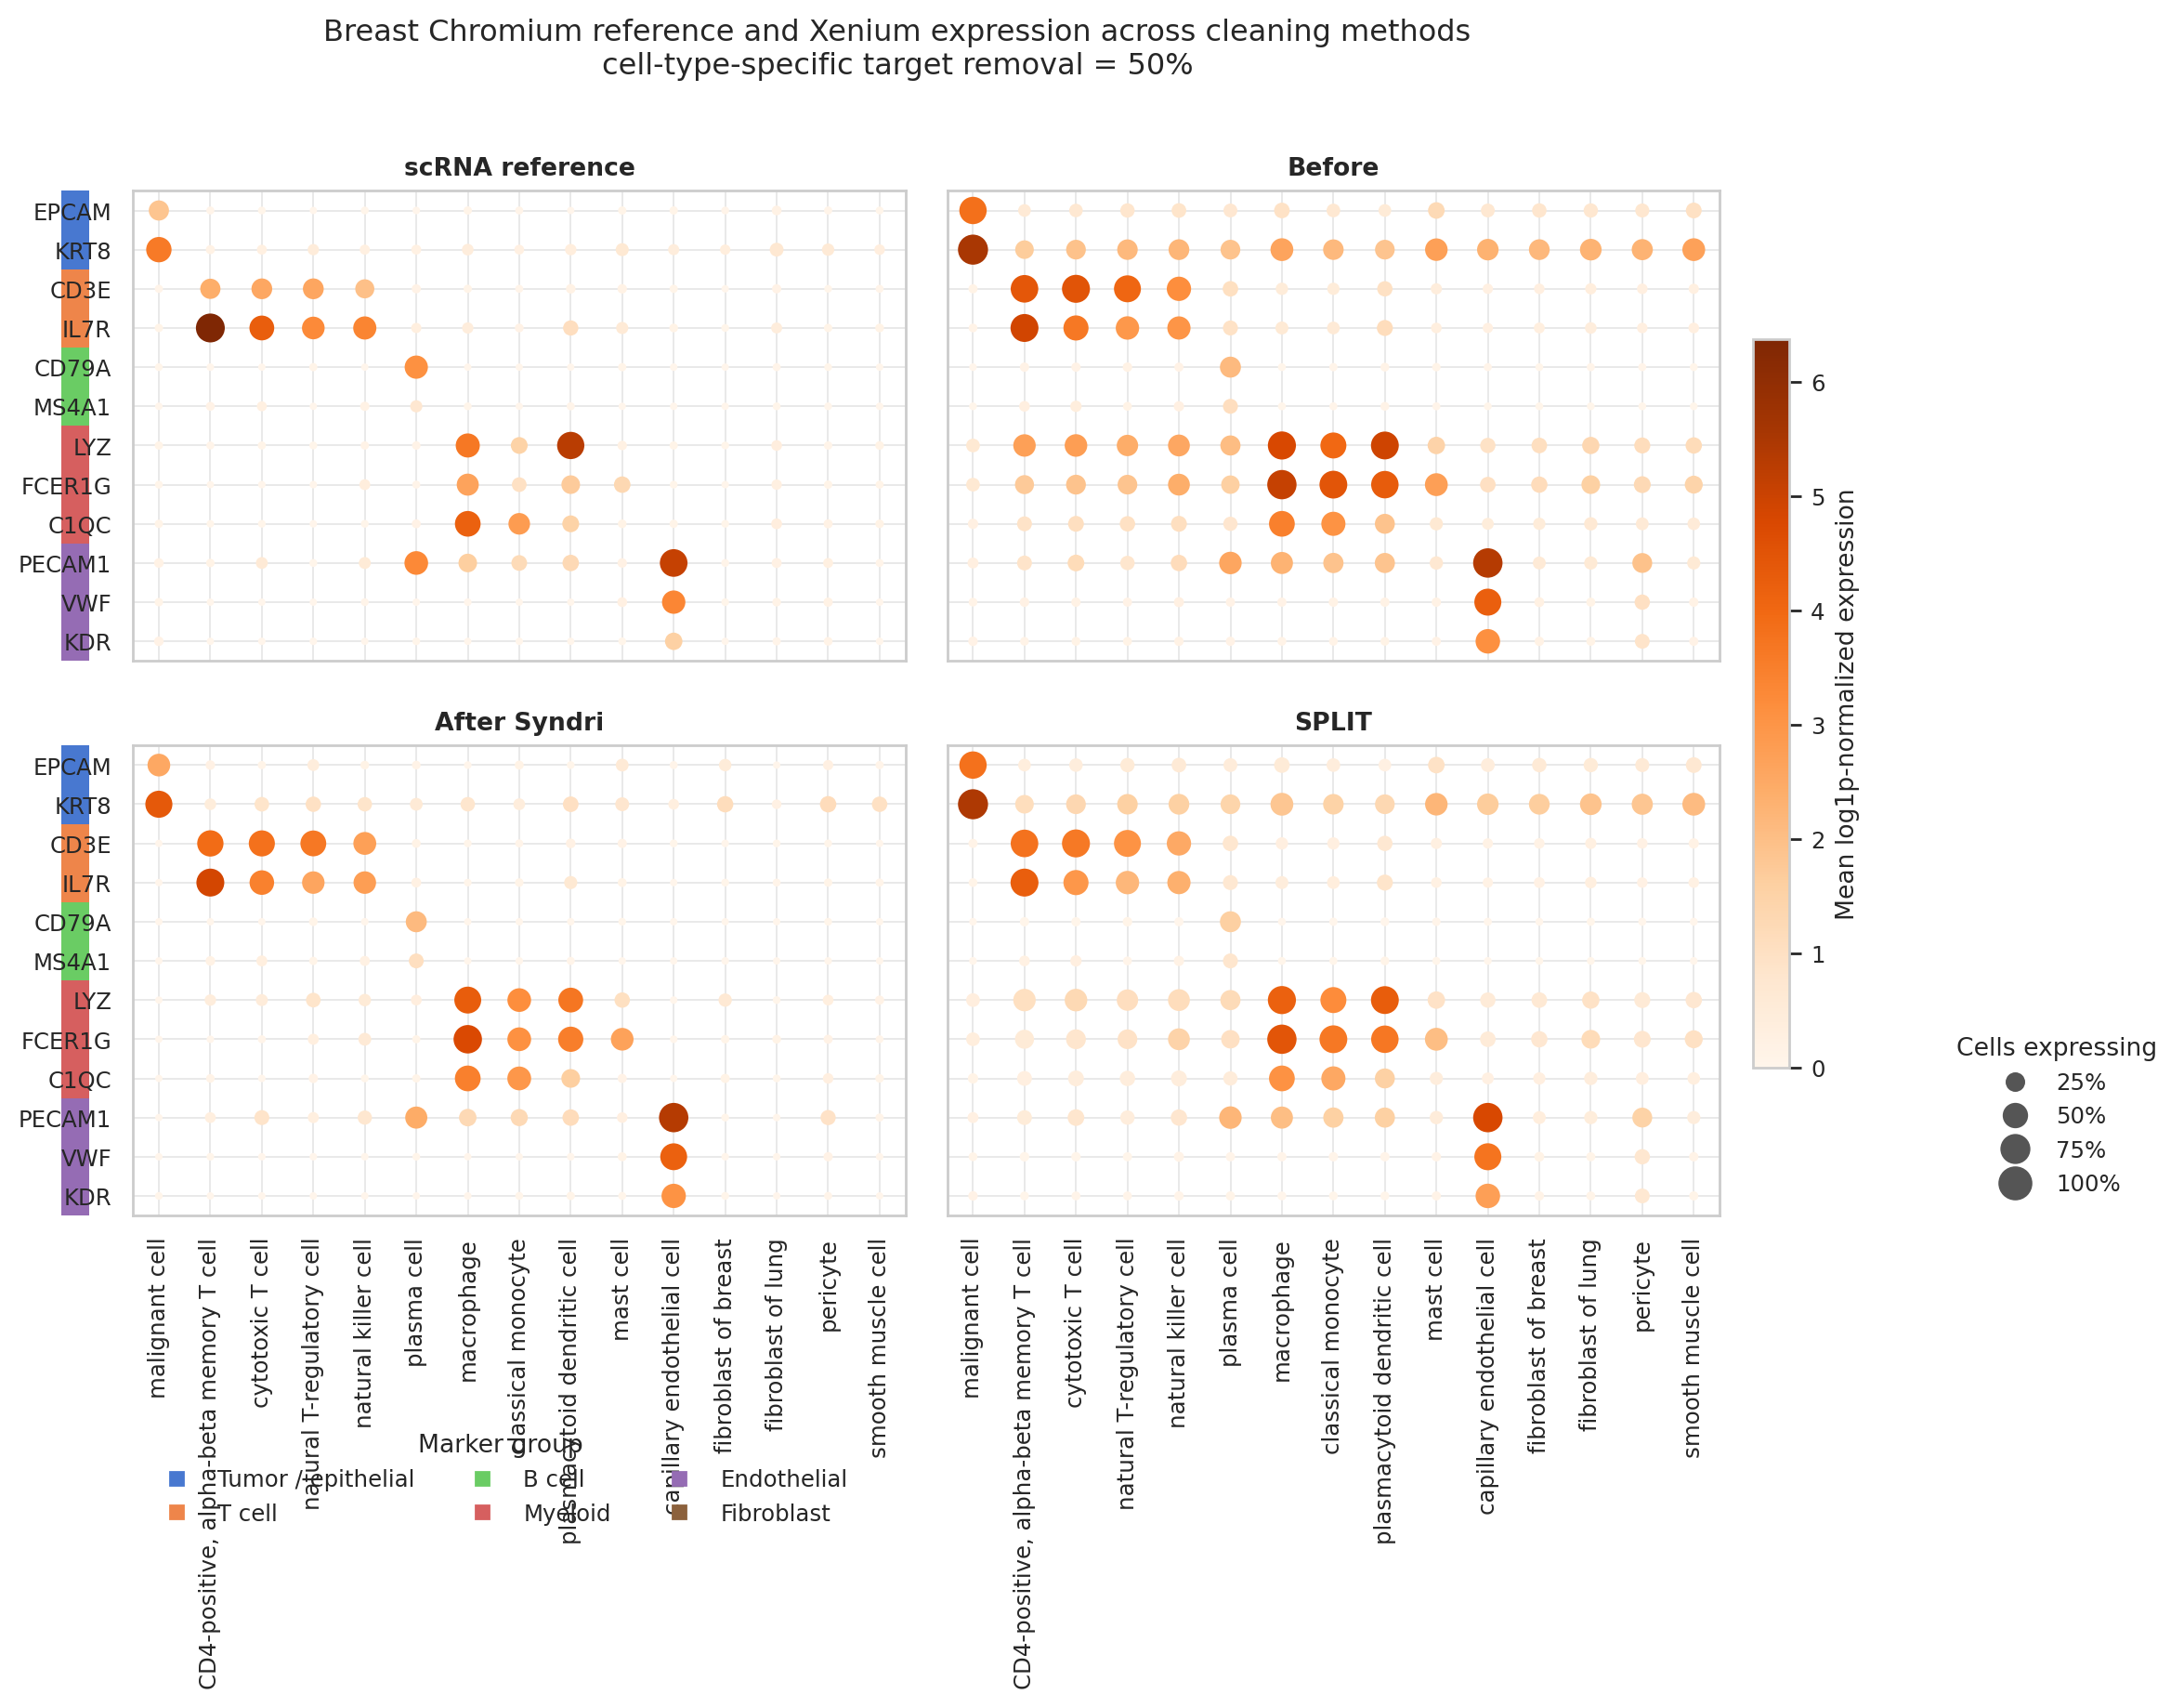

In [28]:
conditions = ['scRNA reference', 'Before', 'After Syndri', 'SPLIT']
gene_order = [gene for gene in requested_genes if gene in genes_use]
gene_to_y = {gene: i for i, gene in enumerate(gene_order)}
gene_group = {gene: group for group, genes in MARKER_GENES.items() for gene in genes}

# Arrange cell types in the same order as the marker blocks to form a
# block diagonal. Add or revise entries when cell-type labels change.
CELL_TYPE_TO_MARKER_GROUP = {
    'malignant cell': 'Tumor / epithelial',
    'cytotoxic T cell': 'T cell',
    'CD4-positive, alpha-beta memory T cell': 'T cell',
    'CD4-positive, alpha-beta regulatory T cell': 'T cell',
    'natural T-regulatory cell': 'T cell',
    'natural killer cell': 'T cell',
    'plasma cell': 'B cell',
    'classical monocyte': 'Myeloid',
    'macrophage': 'Myeloid',
    'mast cell': 'Myeloid',
    'plasmacytoid dendritic cell': 'Myeloid',
    'capillary endothelial cell': 'Endothelial',
    'fibroblast of lung': 'Fibroblast',
    'fibroblast of breast': 'Fibroblast',
    'pericyte': 'Fibroblast',
    'smooth muscle cell': 'Fibroblast',
}
# CELL_TYPE_TO_MARKER_GROUP = {ct:ct for ct in MARKER_GENES.keys()}
marker_group_order = list(MARKER_GENES)
marker_group_rank = {group: rank for rank, group in enumerate(marker_group_order)}

# Use the cleaned panel to rank cell types within their expected block.
# This affects ordering only; both panels still display their own values.
after = pooled[pooled['condition'].eq('After Syndri')].copy()
after['marker_group'] = after['gene'].map(gene_group)
group_scores = (
    after.groupby(['cell_type', 'marker_group'], observed=True)['mean_expression']
    .mean()
    .unstack(fill_value=0)
)

# For an unmapped label, fall back to the marker group with the largest
# mean scaled expression and print the inferred assignment for review.
inferred_assignments = {}
for cell_type in cell_type_order:
    if cell_type not in CELL_TYPE_TO_MARKER_GROUP:
        inferred_assignments[cell_type] = group_scores.loc[cell_type].idxmax()
if inferred_assignments:
    print('Data-driven marker-group assignments for unmapped cell types:')
    display(pd.Series(inferred_assignments, name='marker_group').to_frame())

def cell_type_sort_key(cell_type):
    group = (CELL_TYPE_TO_MARKER_GROUP[cell_type]
             if cell_type in CELL_TYPE_TO_MARKER_GROUP
             else inferred_assignments[cell_type])
    score = group_scores.loc[cell_type, group] if group in group_scores.columns else 0
    return marker_group_rank[group], -score, cell_type

cell_type_order = sorted(cell_type_order, key=cell_type_sort_key)
cell_type_to_x = {cell_type: i for i, cell_type in enumerate(cell_type_order)}
group_palette = dict(zip(MARKER_GENES, sns.color_palette('muted', n_colors=len(MARKER_GENES))))

fig = plt.figure(figsize=(max(12, 0.15 * len(cell_type_order) * 2), 0.18 * len(gene_order) + 5), dpi=200)
grid = fig.add_gridspec(2, 3, width_ratios=[0.035, 1, 1], hspace=0.18, wspace=0.08)
strip_axes = [fig.add_subplot(grid[row, 0]) for row in range(2)]
ax_grid = np.empty((2, 2), dtype=object)
ax_grid[0, 0] = fig.add_subplot(grid[0, 1])
ax_grid[0, 1] = fig.add_subplot(grid[0, 2], sharex=ax_grid[0, 0], sharey=ax_grid[0, 0])
ax_grid[1, 0] = fig.add_subplot(grid[1, 1], sharex=ax_grid[0, 0], sharey=ax_grid[0, 0])
ax_grid[1, 1] = fig.add_subplot(grid[1, 2], sharex=ax_grid[0, 0], sharey=ax_grid[0, 0])
axes = ax_grid.ravel().tolist()

for strip_ax in strip_axes:
    for i, gene in enumerate(gene_order):
        strip_ax.add_patch(plt.Rectangle((0, i - 0.5), 1, 1, color=group_palette[gene_group[gene]], ec='none'))
    strip_ax.set(xlim=(0, 1), ylim=(len(gene_order) - 0.5, -0.5))
    strip_ax.axis('off')

expression_vmax = float(pooled['mean_expression'].max())
scatter = None
for ax, condition in zip(axes, conditions):
    data = pooled[pooled['condition'].eq(condition)]
    scatter = ax.scatter(
        data['cell_type'].map(cell_type_to_x), data['gene'].map(gene_to_y),
        s=8 + 140 * data['fraction_expressing'],
        c=data['mean_expression'], cmap='Oranges', vmin=0, vmax=expression_vmax,
        edgecolor='none',
    )
    ax.set_title(condition, fontweight='bold')
    ax.set_xticks(range(len(cell_type_order)), cell_type_order, rotation=90)
    ax.set_yticks(range(len(gene_order)))
    ax.set_yticklabels(gene_order)
    ax.set(xlim=(-0.5, len(cell_type_order) - 0.5), ylim=(len(gene_order) - 0.5, -0.5))
    ax.grid(color='#e5e5e5', linewidth=0.6)
    ax.set_axisbelow(True)

# Shared axes: show cell-type labels only on the bottom row.
for ax in axes[:2]:
    ax.tick_params(axis='x', labelbottom=False)
for ax in (axes[1], axes[3]):
    ax.tick_params(axis='y', labelleft=False)

colorbar = fig.colorbar(scatter, ax=axes, fraction=0.022, pad=0.02)
colorbar.set_label('Mean log1p-normalized expression')
size_values = [0.25, 0.50, 0.75, 1.00]
size_handles = [Line2D([], [], marker='o', linestyle='', color='#555555',
                       markersize=np.sqrt(8 + 140 * value)) for value in size_values]
axes[-1].legend(size_handles, [f'{value:.0%}' for value in size_values],
               title='Cells expressing', frameon=False, bbox_to_anchor=(1.28, 0), loc='lower left')
group_handles = [Line2D([], [], marker='s', linestyle='', color=color, label=group)
                 for group, color in group_palette.items()]
axes[2].legend(handles=group_handles, title='Marker group', frameon=False,
               bbox_to_anchor=(0, -0.42), loc='upper left', ncol=3)
fig.suptitle(f'Breast Chromium reference and Xenium expression across cleaning methods\n'
             f'cell-type-specific target removal = {TARGET_REMOVED_FRACTION:.0%}', y=1.01)
fig.savefig(OUTPUT_DIR / 'xenium_reference_syndri_split_dotplot.png', dpi=300, bbox_inches='tight')
fig.savefig(OUTPUT_DIR / 'xenium_reference_syndri_split_dotplot.pdf', bbox_inches='tight')
plt.show()

## Gene–gene coexpression before and after Syndri cleaning

Each matrix entry is the fraction of Xenium cells in the 19-slice cohort where both genes have a count greater than `DETECTION_THRESHOLD`. Genes come from the loaded hierarchical marker file and are matched to the Xenium panel by Ensembl ID. They are ordered by hierarchy stage, parent group, cell type, and gene; duplicate genes use their first group in that order. CSV matrices retain Ensembl IDs, while the plot displays Xenium gene symbols. The original and Syndri-cleaned panels share one fraction scale and identical gene order.

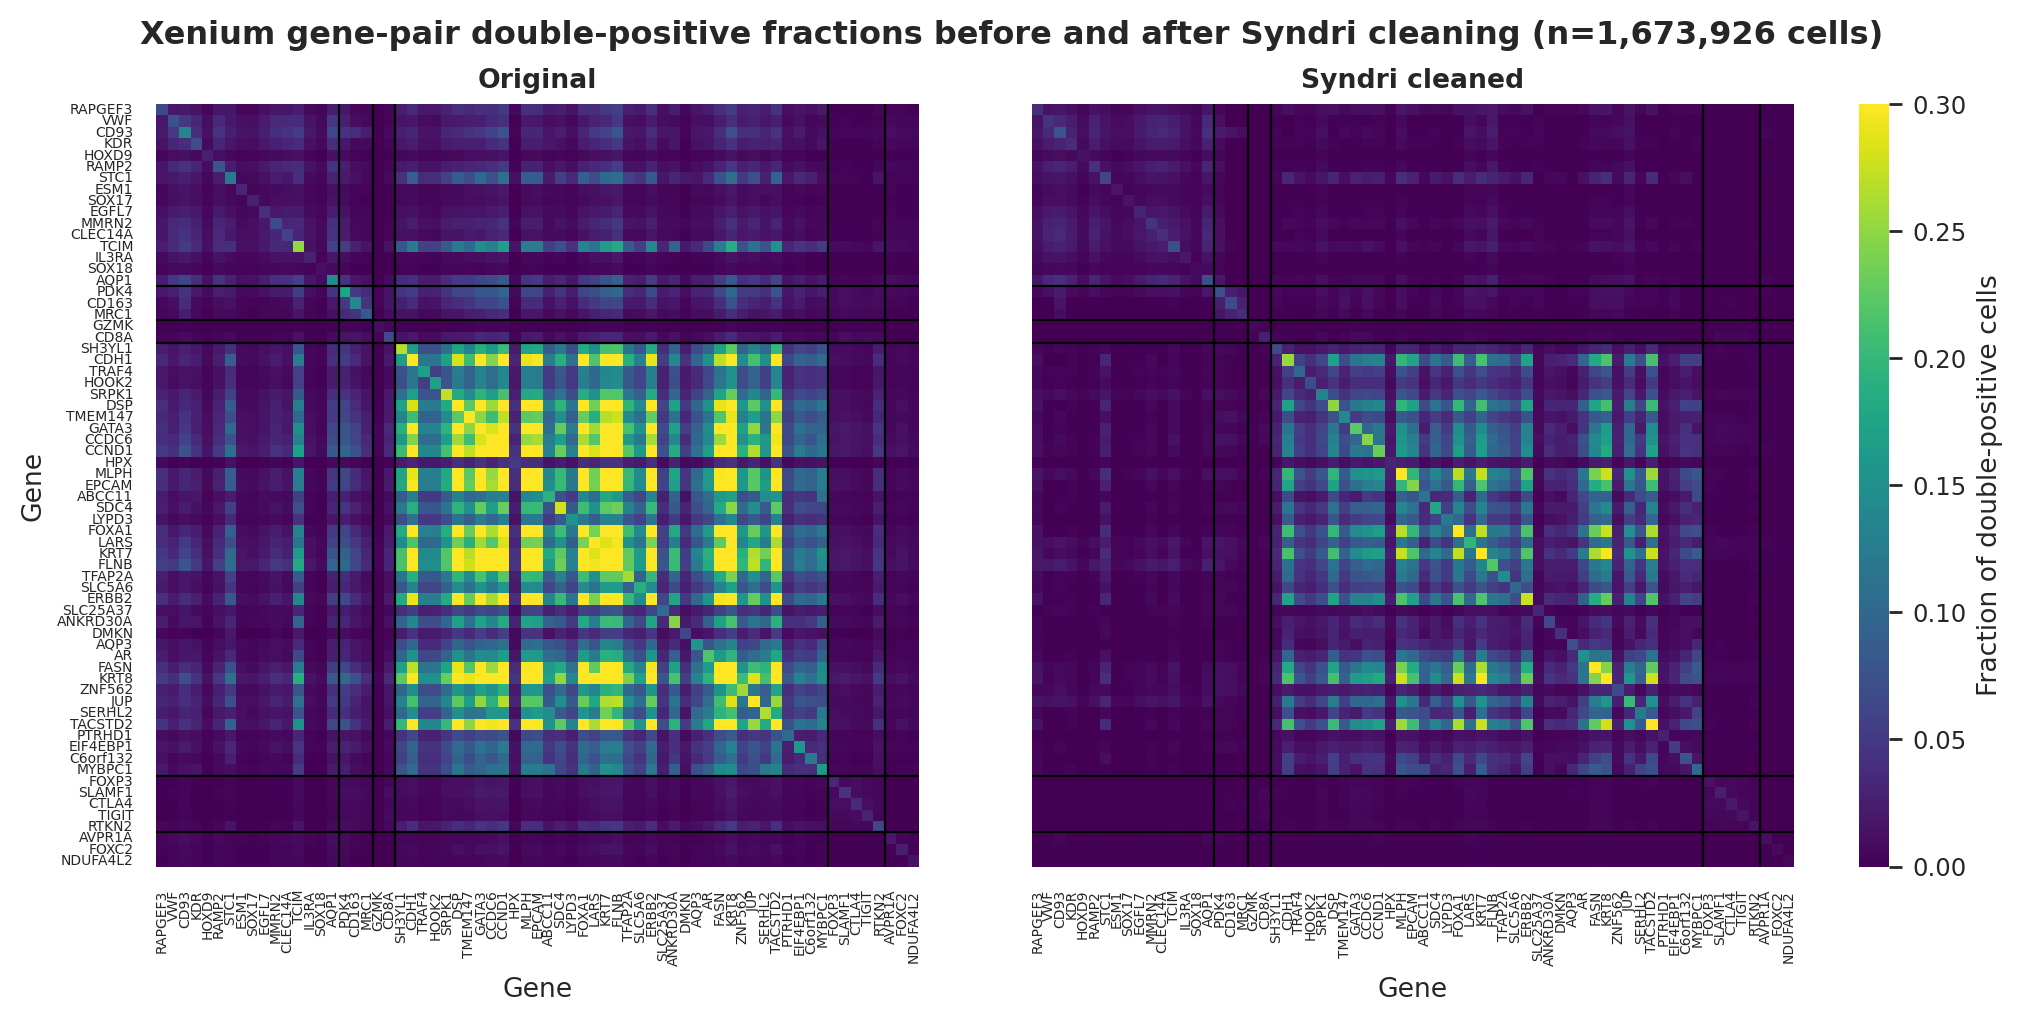

In [35]:
def double_positive_fraction_from_stats(stats):
    n_cells = stats['n_cells']
    if n_cells == 0:
        raise ValueError('At least one cell is required to compute double-positive fractions')
    fraction = stats['cross_product'] / n_cells
    return pd.DataFrame(
        fraction, index=coexpression_genes_use, columns=coexpression_genes_use
    )


coexpression = {
    condition: double_positive_fraction_from_stats(stats)
    for condition, stats in coexpression_stats.items()
}
for condition, matrix in coexpression.items():
    filename_condition = condition.lower().replace(' ', '_')
    matrix.to_csv(
        OUTPUT_DIR / f'xenium_{filename_condition}_gene_double_positive_fraction.csv'
    )

shared_vmax = max(float(matrix.to_numpy().max()) for matrix in coexpression.values())
fig = plt.figure(figsize=(10, 5), dpi=200, constrained_layout=True)
grid = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.035])
heatmap_axes = [fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1])]
colorbar_axis = fig.add_subplot(grid[0, 2])

for index, (ax, condition) in enumerate(zip(heatmap_axes, ('Original', 'Syndri cleaned'))):
    sns.heatmap(
        coexpression[condition], ax=ax, cmap='viridis', vmin=0, vmax=0.3,
        square=True, xticklabels=coexpression_gene_labels,
        yticklabels=coexpression_gene_labels,
        cbar=index == 1, cbar_ax=colorbar_axis if index == 1 else None,
        cbar_kws={'label': 'Fraction of double-positive cells'},
    )
    ax.set_title(condition, fontweight='bold')
    ax.set_xlabel('Gene')
    ax.set_ylabel('Gene' if index == 0 else '')
    ax.tick_params(axis='x', rotation=90, labelsize=5)
    ax.tick_params(axis='y', rotation=0, labelsize=5)
    if index == 1:
        ax.set_yticklabels([])
    # Delineate hierarchical marker groups in the shared gene order.
    boundary = 0
    for genes in COEXPRESSION_GENES_BY_GROUP.values():
        boundary += sum(gene in coexpression_genes_use for gene in genes)
        if boundary < len(coexpression_genes_use):
            ax.axhline(boundary, color='black', linewidth=0.8)
            ax.axvline(boundary, color='black', linewidth=0.8)

fig.suptitle(
    f"Xenium gene-pair double-positive fractions before and after Syndri cleaning (n={coexpression_stats['Original']['n_cells']:,} cells)",
    fontweight='bold',
)
fig.savefig(OUTPUT_DIR / 'xenium_original_vs_syndri_double_positive_heatmap.png', dpi=300, bbox_inches='tight')
fig.savefig(OUTPUT_DIR / 'xenium_original_vs_syndri_double_positive_heatmap.pdf', bbox_inches='tight')
plt.show()

## Outputs

The notebook writes publication-resolution dot-plot and double-positive-fraction heatmap PNG/PDF files, the original and Syndri-cleaned fraction matrices as CSV files, pooled and per-slice dot-plot tables, and selected Syndri thresholds to `OUTPUT_DIR`.